Database can be downloaded here: https://drive.google.com/drive/folders/1b-eyaGi5w7lHwkrYIBZeW6H2YK2ZulNO?usp=sharing

In [17]:
%pip -q install torchmetrics torch-fidelity

In [18]:
import os, io, json, time, math, copy, random, shutil, zipfile, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.utils import make_grid, save_image

# ------------------------------- configuration -------------------------------
SEED = 42
TRAIN_RATIO = 0.80            # identical split to Week 9 (800 train / 200 test)
NEAR_DUP_HAMMING = 6
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 1000                 # 12 steps/epoch -> 12,000 optimiser steps per model
LR = 2e-4
WARMUP_STEPS = 200
GRAD_CLIP = 1.0
EMA_DECAY = 0.999
DDPM_T = 500
FLOW_STEPS = 100              # Euler steps; a 25-step run is also evaluated
EVAL_EVERY = 50               # epochs between held-out loss evaluations
PROGRESS_EVERY = 200          # epochs between fixed-noise sample grids
N_EVAL_SAMPLES = 1000

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
USE_AMP = device.type == "cuda"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU", "| AMP:", AMP_DTYPE if USE_AMP else "off")

WORK = Path("/content") if Path("/content").exists() else Path.cwd()
RESULTS = WORK / "comp8410_week10_results"
if RESULTS.exists(): shutil.rmtree(RESULTS)
(RESULTS / "progress").mkdir(parents=True)

Device: cuda | NVIDIA A100-SXM4-80GB | AMP: torch.bfloat16


In [ ]:
ZIP_PATH = None   
if ZIP_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    zips = [n for n in uploaded if n.lower().endswith(".zip")]
    if not zips:
        raise ValueError("Please upload a ZIP file.")
    ZIP_PATH = WORK / zips[0]

extract_dir = WORK / "beauty_api_extracted"
if extract_dir.exists(): shutil.rmtree(extract_dir)
extract_dir.mkdir(parents=True)
with zipfile.ZipFile(ZIP_PATH) as zf:                     # safe extraction (no path traversal)
    for m in zf.infolist():
        dest = (extract_dir / m.filename).resolve()
        if dest != extract_dir.resolve() and extract_dir.resolve() not in dest.parents:
            continue
        if m.is_dir():
            dest.mkdir(parents=True, exist_ok=True)
        else:
            dest.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(m) as s, open(dest, "wb") as d: shutil.copyfileobj(s, d)
print("Extracted to", extract_dir)

Saving the-beauty-api-sample-dataset.zip to the-beauty-api-sample-dataset (1).zip
Extracted to /content/beauty_api_extracted


In [20]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
candidates = sorted(p for p in extract_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def dhash(img, size=8):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).flatten())

unique, hashes, seen, bad, exact_dups = [], [], set(), [], 0
for p in tqdm(candidates, desc="Validating"):
    try:
        with Image.open(p) as im: im.verify()
        digest = hashlib.sha256(p.read_bytes()).hexdigest()
        if digest in seen:
            exact_dups += 1; continue
        seen.add(digest)
        with Image.open(p) as im: hashes.append(dhash(im))
        unique.append(p)
    except (UnidentifiedImageError, OSError, ValueError):
        bad.append(str(p))
print(f"Files: {len(candidates)} | valid unique: {len(unique)} | exact duplicates: {exact_dups} | invalid: {len(bad)}")

# near-duplicate groups by leader clustering: an image joins a group only if it is within the threshold
# of that group's first image, so chains of small differences cannot merge unrelated images.
H = np.unpackbits(np.stack(hashes), axis=1).astype(bool)
dist = (H[:, None, :] != H[None, :, :]).sum(-1)
pairs = np.argwhere(np.triu(dist <= NEAR_DUP_HAMMING, k=1))
leaders, groups = [], {}
for i in range(len(unique)):
    close = [l for l in leaders if dist[i, l] <= NEAR_DUP_HAMMING]
    if close:
        groups[min(close, key=lambda l: dist[i, l])].append(i)
    else:
        leaders.append(i); groups[i] = [i]
largest = max(len(g) for g in groups.values())
if largest > 0.05 * len(unique):
    print(f"WARNING: largest near-duplicate group has {largest} images - consider lowering NEAR_DUP_HAMMING")
print(f"Near-duplicate pairs: {len(pairs)} | groups: {len(groups)} | largest group: {largest}")

Validating:   0%|          | 0/1000 [00:00<?, ?it/s]

Files: 1000 | valid unique: 1000 | exact duplicates: 0 | invalid: 0
Near-duplicate pairs: 129 | groups: 944 | largest group: 6


In [21]:
# group-aware split: near-duplicates always land on the same side
group_list = list(groups.values())
random.Random(SEED).shuffle(group_list)
n_train_target = int(len(unique) * TRAIN_RATIO)
train_idx, test_idx = [], []
for g in group_list:
    (train_idx if len(train_idx) < n_train_target else test_idx).extend(g)
train_files = [unique[i] for i in train_idx]
test_files = [unique[i] for i in test_idx]
train_set = set(train_idx)
cross = sum(1 for a, b in pairs if (a in train_set) != (b in train_set))
print(f"Train: {len(train_files)} | Test: {len(test_files)} | near-duplicate pairs crossing the split: {cross}")
assert len(test_files) >= 0.15 * len(unique), "Test split is too small - near-duplicate grouping is too aggressive."

Train: 800 | Test: 200 | near-duplicate pairs crossing the split: 12


Preprocessing:   0%|          | 0/800 [00:00<?, ?it/s]

Preprocessing:   0%|          | 0/200 [00:00<?, ?it/s]

Train tensor: (800, 3, 64, 64) | Test tensor: (200, 3, 64, 64)


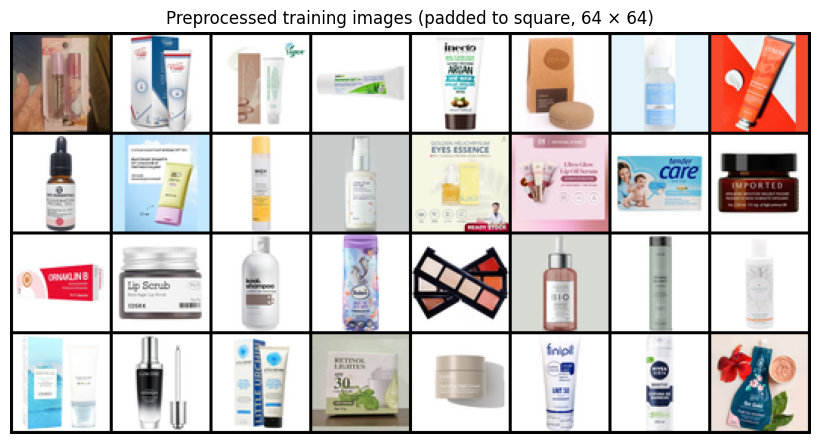

In [22]:
def to_square(img, size=IMAGE_SIZE):
    """Pad to a square with the image's own border colour (keeps aspect ratio), then resize."""
    img = img.convert("RGB")
    a = np.asarray(img)
    border = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    fill = tuple(int(v) for v in np.median(border, axis=0))
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((size, size), Image.Resampling.LANCZOS)

def load_tensor(files):
    arr = np.stack([np.asarray(to_square(Image.open(f)), dtype=np.uint8) for f in tqdm(files, desc="Preprocessing")])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(127.5).sub(1.0)     # [-1, 1]

X_train = load_tensor(train_files).to(device)
X_test = load_tensor(test_files).to(device)
print("Train tensor:", tuple(X_train.shape), "| Test tensor:", tuple(X_test.shape))

def batches(X, bs=BATCH_SIZE, shuffle=True, drop_last=True, gen=None):
    idx = torch.randperm(len(X), generator=gen, device="cpu") if shuffle else torch.arange(len(X))
    stop = len(X) - (len(X) % bs if drop_last else 0)
    for i in range(0, stop, bs):
        yield X[idx[i:i + bs].to(X.device)]

def show(t, title, path=None, nrow=8):
    g = make_grid((t[:64].detach().cpu() + 1) / 2, nrow=nrow).clamp(0, 1)
    if path: save_image(g, path)
    plt.figure(figsize=(nrow * 1.3, max(2, g.shape[1] / g.shape[2] * nrow * 1.3)))
    plt.imshow(g.permute(1, 2, 0)); plt.title(title); plt.axis("off"); plt.show()

show(X_train[:32], "Preprocessed training images (padded to square, 64 × 64)", RESULTS / "real_train_grid.png")

In [23]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / max(half - 1, 1))
    args = t[:, None] * freqs[None, :]
    emb = torch.cat([torch.sin(args), torch.cos(args)], dim=1)
    return F.pad(emb, (0, 1)) if dim % 2 else emb

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch); self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch); self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class TimeUNet(nn.Module):
    """Unchanged from v1 except TIME_SCALE: t in [0, 1] is mapped to [0, 1000] before the sinusoidal embedding."""
    TIME_SCALE = 1000.0
    def __init__(self, in_channels=3, base=64, time_dim=256):
        super().__init__()
        self.time_dim = time_dim
        self.time_mlp = nn.Sequential(nn.Linear(time_dim, time_dim * 4), nn.SiLU(), nn.Linear(time_dim * 4, time_dim))
        self.in_conv = nn.Conv2d(in_channels, base, 3, padding=1)
        self.down1 = ResBlock(base, base, time_dim)
        self.downsample1 = nn.Conv2d(base, base * 2, 4, stride=2, padding=1)
        self.down2 = ResBlock(base * 2, base * 2, time_dim)
        self.downsample2 = nn.Conv2d(base * 2, base * 4, 4, stride=2, padding=1)
        self.mid1 = ResBlock(base * 4, base * 4, time_dim); self.mid2 = ResBlock(base * 4, base * 4, time_dim)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 4, stride=2, padding=1)
        self.up_block2 = ResBlock(base * 4, base * 2, time_dim)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 4, stride=2, padding=1)
        self.up_block1 = ResBlock(base * 2, base, time_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 3, 3, padding=1))
    def forward(self, x, t):
        t_emb = self.time_mlp(sinusoidal_embedding(t * self.TIME_SCALE, self.time_dim))
        d1 = self.down1(self.in_conv(x), t_emb)
        d2 = self.down2(self.downsample1(d1), t_emb)
        h = self.mid2(self.mid1(self.downsample2(d2), t_emb), t_emb)
        h = self.up_block2(torch.cat([self.up2(h), d2], 1), t_emb)
        h = self.up_block1(torch.cat([self.up1(h), d1], 1), t_emb)
        return self.out(h)

count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)

# Embedding check: distance between the embeddings of adjacent DDPM steps
tt = torch.tensor([DDPM_T - 2, DDPM_T - 1], dtype=torch.float) / (DDPM_T - 1)
e_old, e_new = sinusoidal_embedding(tt, 256), sinusoidal_embedding(tt * 1000, 256)
print(f"Adjacent-step embedding distance: v1 {(e_old[0]-e_old[1]).norm():.4f} | v2 {(e_new[0]-e_new[1]).norm():.3f}")

Adjacent-step embedding distance: v1 0.0055 | v2 4.989


In [24]:
class DDPM:
    """Ho et al. (2020) with a linear beta schedule rescaled for T steps (Nichol and Dhariwal, 2021)."""
    def __init__(self, T=500):
        self.T = T
        scale = 1000 / T
        self.betas = torch.linspace(1e-4 * scale, 0.02 * scale, T, device=device)
        self.alphas = 1 - self.betas
        self.ab = torch.cumprod(self.alphas, 0)
    def tnorm(self, t): return t.float() / (self.T - 1)
    def q_sample(self, x0, t, noise):
        a = self.ab[t].sqrt().view(-1, 1, 1, 1); b = (1 - self.ab[t]).sqrt().view(-1, 1, 1, 1)
        return a * x0 + b * noise
    def loss(self, model, x0, t=None, noise=None):
        t = torch.randint(0, self.T, (x0.size(0),), device=device) if t is None else t
        noise = torch.randn_like(x0) if noise is None else noise
        return F.mse_loss(model(self.q_sample(x0, t, noise), self.tnorm(t)).float(), noise)
    @torch.no_grad()
    def sample(self, model, n, gen=None):
        model.eval()
        x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, device=device, generator=gen)
        for s in reversed(range(self.T)):
            t = torch.full((n,), s, device=device, dtype=torch.long)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                eps = model(x, self.tnorm(t)).float()
            mean = (x - self.betas[s] / (1 - self.ab[s]).sqrt() * eps) / self.alphas[s].sqrt()
            x = mean + self.betas[s].sqrt() * torch.randn(x.shape, device=device, generator=gen) if s > 0 else mean
        return x.clamp(-1, 1)
    nfe = property(lambda self: self.T)

class FlowMatching:
    """Conditional flow matching with a straight (rectified) path from noise (t=0) to data (t=1)."""
    def __init__(self, steps=100): self.steps = steps
    def loss(self, model, x1, t=None, eps=None):
        t = torch.rand(x1.size(0), device=device) if t is None else t
        eps = torch.randn_like(x1) if eps is None else eps
        tv = t.view(-1, 1, 1, 1)
        return F.mse_loss(model((1 - tv) * eps + tv * x1, t).float(), x1 - eps)
    @torch.no_grad()
    def sample(self, model, n, gen=None, steps=None):
        model.eval(); steps = steps or self.steps
        x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, device=device, generator=gen)
        for i in range(steps):
            t = torch.full((n,), i / steps, device=device)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                v = model(x, t).float()
            x = x + v / steps
        return x.clamp(-1, 1)
    nfe = property(lambda self: self.steps)

ddpm, flow = DDPM(DDPM_T), FlowMatching(FLOW_STEPS)
print(f"DDPM: signal left at t=T: sqrt(alpha_bar_T) = {ddpm.ab[-1].sqrt().item():.4f}")

DDPM: signal left at t=T: sqrt(alpha_bar_T) = 0.0061


In [25]:
@torch.no_grad()
def heldout_loss(method, model, X, seed=SEED):
    """Deterministic: fixed noise and an evenly spaced grid of t, so the curve is not jumpy."""
    model.eval(); g = torch.Generator(device=device).manual_seed(seed); tot = 0.0
    for i in range(0, len(X), 100):
        x = X[i:i + 100]; n = x.size(0)
        noise = torch.randn(x.shape, device=device, generator=g)
        if isinstance(method, DDPM):
            t = (torch.arange(n, device=device) * method.T // n).long()
        else:
            t = (torch.arange(n, device=device).float() + 0.5) / n
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            tot += method.loss(model, x, t, noise).item() * n
    return tot / len(X)

def train(name, method):
    set_seed(SEED)
    model = TimeUNet().to(device); ema = copy.deepcopy(model).eval()
    for p in ema.parameters(): p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    gen = torch.Generator().manual_seed(SEED)
    fixed = torch.Generator(device=device)
    hist = {"train": [], "eval_epoch": [], "heldout": [], "heldout_ema": []}
    steps_per_epoch = len(X_train) // BATCH_SIZE
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); run = 0.0
        idx = torch.randperm(len(X_train), generator=gen)
        for b in range(steps_per_epoch):
            x = X_train[idx[b * BATCH_SIZE:(b + 1) * BATCH_SIZE].to(device)]
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = method.loss(model, x)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt); scaler.update(); sched.step()
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()): pe.lerp_(pm, 1 - EMA_DECAY)
            run += loss.item()
        hist["train"].append(run / steps_per_epoch)
        if epoch % EVAL_EVERY == 0 or epoch == 1:
            hist["eval_epoch"].append(epoch)
            hist["heldout"].append(heldout_loss(method, model, X_test))
            hist["heldout_ema"].append(heldout_loss(method, ema, X_test))
            print(f"{name} | epoch {epoch:4d} | train {hist['train'][-1]:.4f} | held-out {hist['heldout'][-1]:.4f} | held-out (EMA) {hist['heldout_ema'][-1]:.4f}")
        if epoch % PROGRESS_EVERY == 0:
            fixed.manual_seed(SEED)
            save_image((method.sample(ema, 36, gen=fixed) + 1) / 2, RESULTS / "progress" / f"{name.lower()}_epoch{epoch:04d}.png", nrow=6)
    if device.type == "cuda": torch.cuda.synchronize()
    hist["minutes"] = (time.time() - t0) / 60
    hist["peak_gib"] = torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else float("nan")
    hist["steps"] = EPOCHS * steps_per_epoch
    print(f"{name}: {hist['minutes']:.2f} min | {hist['steps']} steps | peak GPU {hist['peak_gib']:.2f} GiB")
    return model, ema, hist

In [26]:
ddpm_model, ddpm_ema, ddpm_hist = train("DDPM", ddpm)

DDPM | epoch    1 | train 1.1064 | held-out 1.0385 | held-out (EMA) 1.1455
DDPM | epoch   50 | train 0.0277 | held-out 0.0309 | held-out (EMA) 0.2655
DDPM | epoch  100 | train 0.0206 | held-out 0.0224 | held-out (EMA) 0.0707
DDPM | epoch  150 | train 0.0172 | held-out 0.0197 | held-out (EMA) 0.0394
DDPM | epoch  200 | train 0.0170 | held-out 0.0179 | held-out (EMA) 0.0256
DDPM | epoch  250 | train 0.0156 | held-out 0.0171 | held-out (EMA) 0.0195
DDPM | epoch  300 | train 0.0151 | held-out 0.0166 | held-out (EMA) 0.0170
DDPM | epoch  350 | train 0.0163 | held-out 0.0161 | held-out (EMA) 0.0159
DDPM | epoch  400 | train 0.0153 | held-out 0.0158 | held-out (EMA) 0.0152
DDPM | epoch  450 | train 0.0136 | held-out 0.0152 | held-out (EMA) 0.0148
DDPM | epoch  500 | train 0.0146 | held-out 0.0153 | held-out (EMA) 0.0144
DDPM | epoch  550 | train 0.0142 | held-out 0.0148 | held-out (EMA) 0.0142
DDPM | epoch  600 | train 0.0112 | held-out 0.0146 | held-out (EMA) 0.0140
DDPM | epoch  650 | train

In [27]:
flow_model, flow_ema, flow_hist = train("Flow", flow)

Flow | epoch    1 | train 1.6484 | held-out 1.4157 | held-out (EMA) 1.7832
Flow | epoch   50 | train 0.1291 | held-out 0.1387 | held-out (EMA) 0.5888
Flow | epoch  100 | train 0.1094 | held-out 0.1172 | held-out (EMA) 0.2325
Flow | epoch  150 | train 0.1011 | held-out 0.1104 | held-out (EMA) 0.1505
Flow | epoch  200 | train 0.0962 | held-out 0.1040 | held-out (EMA) 0.1198
Flow | epoch  250 | train 0.0971 | held-out 0.1022 | held-out (EMA) 0.1062
Flow | epoch  300 | train 0.0971 | held-out 0.1049 | held-out (EMA) 0.0994
Flow | epoch  350 | train 0.0908 | held-out 0.0980 | held-out (EMA) 0.0957
Flow | epoch  400 | train 0.0884 | held-out 0.0955 | held-out (EMA) 0.0932
Flow | epoch  450 | train 0.0803 | held-out 0.0966 | held-out (EMA) 0.0915
Flow | epoch  500 | train 0.0869 | held-out 0.0960 | held-out (EMA) 0.0905
Flow | epoch  550 | train 0.0777 | held-out 0.0927 | held-out (EMA) 0.0897
Flow | epoch  600 | train 0.0808 | held-out 0.0955 | held-out (EMA) 0.0893
Flow | epoch  650 | train

ms per image: DDPM (500 NFE) 63.23 | Flow (100 NFE) 12.62 | Flow (25 NFE) 3.16


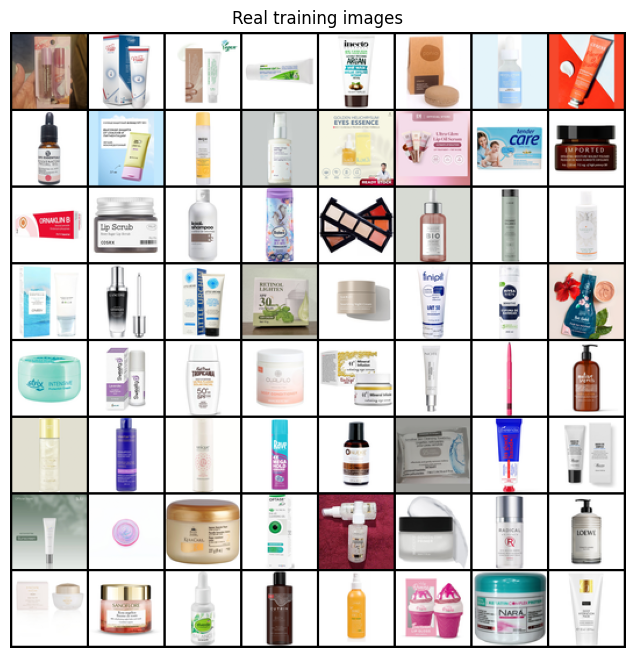

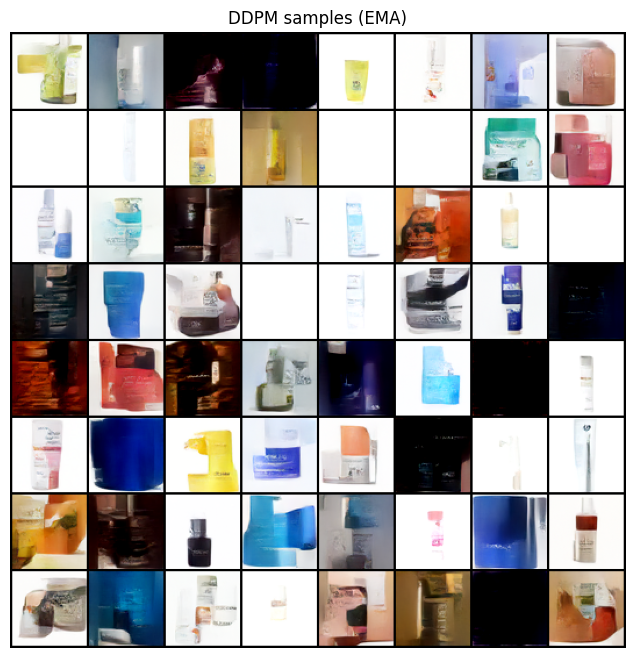

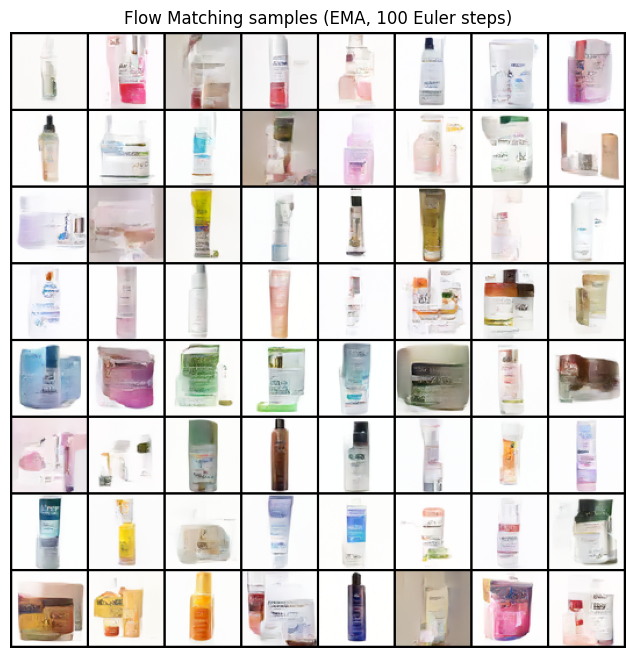

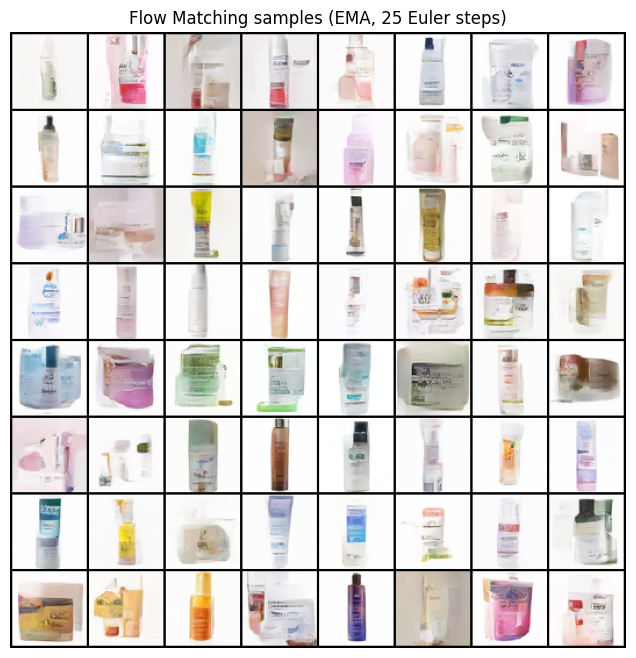

In [28]:
def timed(fn, n=N_EVAL_SAMPLES, bs=250):
    g = torch.Generator(device=device).manual_seed(SEED); out = []
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for i in range(0, n, bs): out.append(fn(min(bs, n - i), g))
    if device.type == "cuda": torch.cuda.synchronize()
    return torch.cat(out), (time.time() - t) / n * 1000      # ms per image

ddpm_samples, ddpm_ms = timed(lambda m, g: ddpm.sample(ddpm_ema, m, g))
flow_samples, flow_ms = timed(lambda m, g: flow.sample(flow_ema, m, g))
flow25_samples, flow25_ms = timed(lambda m, g: flow.sample(flow_ema, m, g, steps=25))
print(f"ms per image: DDPM ({DDPM_T} NFE) {ddpm_ms:.2f} | Flow ({FLOW_STEPS} NFE) {flow_ms:.2f} | Flow (25 NFE) {flow25_ms:.2f}")

def show(t, title, path=None, nrow=8):
    g = make_grid((t[:64].detach().cpu() + 1) / 2, nrow=nrow).clamp(0, 1)
    if path: save_image(g, path)
    plt.figure(figsize=(8, 8)); plt.imshow(g.permute(1, 2, 0)); plt.title(title); plt.axis("off"); plt.show()

show(X_train[:64], "Real training images", RESULTS / "real_train_grid.png")
show(ddpm_samples, "DDPM samples (EMA)", RESULTS / "ddpm_samples.png")
show(flow_samples, f"Flow Matching samples (EMA, {FLOW_STEPS} Euler steps)", RESULTS / "flow_samples.png")
show(flow25_samples, "Flow Matching samples (EMA, 25 Euler steps)", RESULTS / "flow25_samples.png")

In [29]:
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.image.fid import FrechetInceptionDistance

to01 = lambda x: ((x + 1) / 2).clamp(0, 1)
def kid_fid(fake, real, subset=100):
    kid = KernelInceptionDistance(subset_size=min(subset, len(fake), len(real)), normalize=True).to(device)
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, is_real in ((real, True), (fake, False)):
        for i in range(0, len(x), 100):
            b = to01(x[i:i + 100]).float(); kid.update(b, real=is_real); fid.update(b, real=is_real)
    km, ks = kid.compute()
    return km.item() * 1000, ks.item() * 1000, fid.compute().item()

@torch.no_grad()
def mean_pairwise(x, n=200):
    f = x[:n].flatten(1); return torch.cdist(f, f).sum().item() / (len(f) * (len(f) - 1))

@torch.no_grad()
def nn_dist(a, ref):
    a, ref = a.flatten(1), ref.flatten(1)
    return torch.cat([torch.cdist(a[i:i + 250], ref).min(1).values for i in range(0, len(a), 250)])

ref_kid, ref_kid_sd, ref_fid = kid_fid(X_train, X_test)
real_div = mean_pairwise(X_test); test_nn = nn_dist(X_test, X_train).mean().item()

rows = []
for name, xs, ms, nfe, hist in [("DDPM", ddpm_samples, ddpm_ms, DDPM_T, ddpm_hist),
                                 (f"Flow Matching ({FLOW_STEPS} steps)", flow_samples, flow_ms, FLOW_STEPS, flow_hist),
                                 ("Flow Matching (25 steps)", flow25_samples, flow25_ms, 25, flow_hist)]:
    k, ksd, f = kid_fid(xs, X_test)
    rows.append({"model": name, "parameters": count(ddpm_model), "KID_x1e3_vs_test": k, "KID_sd_x1e3": ksd, "FID_vs_test": f,
                 "diversity_ratio": mean_pairwise(xs) / real_div,
                 "nn_train_distance_ratio": nn_dist(xs, X_train).mean().item() / test_nn,
                 "network_evaluations": nfe, "ms_per_image": ms,
                 "training_minutes": hist["minutes"], "peak_gpu_gib": hist["peak_gib"],
                 "final_heldout_loss_ema": hist["heldout_ema"][-1]})
rows.append({"model": "Real train vs test (reference)", "KID_x1e3_vs_test": ref_kid, "KID_sd_x1e3": ref_kid_sd,
             "FID_vs_test": ref_fid, "diversity_ratio": 1.0, "nn_train_distance_ratio": 1.0})
summary = pd.DataFrame(rows)
display(summary.round(3))
summary.to_csv(RESULTS / "comparison_summary.csv", index=False)

,model,parameters,KID_x1e3_vs_test,KID_sd_x1e3,FID_vs_test,diversity_ratio,nn_train_distance_ratio,network_evaluations,ms_per_image,training_minutes,peak_gpu_gib,final_heldout_loss_ema
0,DDPM,5398595.0,70.649,9.625,143.044,1.585,1.203,500.0,63.234,5.351,3.558,0.014
1,Flow Matching (100 steps),5398595.0,23.853,4.070,70.875,0.709,0.846,100.0,12.623,5.134,3.559,0.098
2,Flow Matching (25 steps),5398595.0,23.488,3.494,69.940,0.626,0.785,25.0,3.157,5.134,3.559,0.098
3,Real train vs test (reference),NaN,0.295,1.167,47.051,1.000,1.000,NaN,NaN,NaN,NaN,NaN


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5))
for ax, (name, xs) in zip(axes, [("DDPM", ddpm_samples), ("Flow Matching", flow_samples)]):
    q = xs[:8]; idx = torch.cdist(q.flatten(1), X_train.flatten(1)).argmin(1)
    ax.imshow(make_grid(to01(torch.cat([q, X_train[idx]])).float().cpu(), nrow=8).permute(1, 2, 0))
    ax.axis("off"); ax.set_title(f"{name}: generated (top) and nearest training image (bottom)", fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS / "nearest_neighbours.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (name, h) in zip(ax, [("DDPM noise-prediction MSE", ddpm_hist), ("Flow Matching velocity MSE", flow_hist)]):
    a.plot(range(1, len(h["train"]) + 1), h["train"], lw=0.8, label="train (per epoch)")
    a.plot(h["eval_epoch"], h["heldout"], "o-", ms=3, label="held-out")
    a.plot(h["eval_epoch"], h["heldout_ema"], "s-", ms=3, label="held-out (EMA)")
    a.set_yscale("log"); a.set_title(name); a.set_xlabel("Epoch"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS / "training_curves.png", dpi=160); plt.show()

In [30]:
import importlib.metadata as md_
torch.save(ddpm_ema.state_dict(), RESULTS / "ddpm_ema.pth")
torch.save(flow_ema.state_dict(), RESULTS / "flow_ema.pth")
(RESULTS / "training_history.json").write_text(json.dumps({"ddpm": ddpm_hist, "flow": flow_hist}))
(RESULTS / "split.json").write_text(json.dumps({"train": [str(p.relative_to(extract_dir)) for p in train_files],
                                               "test": [str(p.relative_to(extract_dir)) for p in test_files]}, indent=1))
meta = {
    "seed": SEED, "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS, "steps_per_model": ddpm_hist["steps"],
    "optimizer": f"AdamW lr {LR}, warmup {WARMUP_STEPS} steps, grad clip {GRAD_CLIP}", "ema_decay": EMA_DECAY,
    "amp": str(AMP_DTYPE) if USE_AMP else "off", "unet_parameters": count(ddpm_model), "time_scale": TimeUNet.TIME_SCALE,
    "ddpm": {"T": DDPM_T, "beta_start": ddpm.betas[0].item(), "beta_end": ddpm.betas[-1].item(),
             "sqrt_alpha_bar_T": ddpm.ab[-1].sqrt().item(), "sampler": "ancestral, sigma^2 = beta"},
    "flow": {"path": "linear noise->data", "sampler": "Euler", "steps": [FLOW_STEPS, 25]},
    "preprocessing": "pad to square with median border colour, LANCZOS resize to 64x64, scale to [-1, 1] (same as Week 9)",
    "images": {"valid_unique": len(unique), "train": len(train_files), "test": len(test_files),
               "near_duplicate_pairs": int(len(pairs)), "near_dup_pairs_crossing_split": int(cross)},
    "n_eval_samples": N_EVAL_SAMPLES, "kid_subset_size": 100,
    "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu", "python": platform.python_version(),
    "versions": {p: md_.version(p) for p in ["torch", "torchvision", "torchmetrics", "torch-fidelity", "numpy", "pillow"]},
}
(RESULTS / "metadata.json").write_text(json.dumps(meta, indent=2))
zip_path = shutil.make_archive(str(WORK / "comp8410_week10_results"), "zip", root_dir=RESULTS)
print("Created", zip_path)
try:
    from google.colab import files; files.download(zip_path)
except ImportError:
    pass

Created /content/comp8410_week10_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>